# 02 · The bars to clear: simple forecasts, and NOAA's

Every day at 22:00 UTC, NOAA's Space Weather Prediction Center publishes the probability of a geomagnetic storm on each of the next three days. Before building a model, this notebook scores that forecast, and the simple rules any model should beat, on the same question:

> At 21:00 UTC, what's the chance of a storm (Kp 5- or more at any point) on each of the next three UT days?

**The contenders:**
- **Climatology:** the share of storm days over the past 365 days. Knows the solar cycle, nothing else.
- **Persistence:** how often a storm follows, given today's highest Kp so far.
- **27-day echo:** how often a storm happens, given the highest Kp on the same day one solar rotation earlier.
- **NOAA, as published:** its "minor storm" plus "major-severe storm" probabilities.
- **NOAA, recalibrated:** NOAA forecasts a mid-latitude K index, not the planetary Kp scored here, so its probabilities are also mapped onto Kp, using the training years only.

**Years:** the lookup tables and the recalibration are fitted on 1996–2016. 2017–2021 are held out for choosing models in the next notebook; 2022–2025, the current solar maximum including the May 2024 superstorm, are the test years. (NOAA's reports for 2026 aren't archived until the year ends.)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression

sys.path.insert(0, str(Path("..") / "src"))
from storms import STORM_KP, load_kp, load_noaa_forecasts

kp = load_kp().loc["1995":]
noaa = load_noaa_forecasts()
# NOAA publishes each year's reports as one archive once the year ends, so the test years stop at 2025.
TRAIN, VALID, TEST = ("1996", "2016"), ("2017", "2021"), ("2022", "2025")

# The highest Kp in each UT day, and whether that day had a storm.
daily = kp["kp"].resample("D").max()
storm = (daily >= STORM_KP).astype(float)
# At 21:00 UTC the last three-hour period of the day hasn't happened, so "today so far" is the first seven.
today_so_far = kp.loc[kp.index.hour < 21, "kp"].resample("D").max()
print(f"{len(daily):,} days, {storm.mean():.1%} with a storm; NOAA forecasts for {noaa['issued'].nunique():,} days")

11,593 days, 14.1% with a storm; NOAA forecasts for 10,873 days


## Every forecast, for every issue day and lead time

One row per issue day and lead time (1, 2, or 3 days ahead). Each baseline turns something known at 21:00 UTC into a probability, using how often storms followed it in the training years.

In [2]:
rows = []
for lead in (1, 2, 3):
    issue = daily.index
    target_day = issue + pd.Timedelta(days=lead)
    rows.append(pd.DataFrame({
        "issued": issue, "lead_days": lead, "date": target_day,
        "storm": storm.reindex(target_day).to_numpy(),
        "today": today_so_far.reindex(issue).round().to_numpy(),
        "echo": daily.reindex(target_day - pd.Timedelta(days=27)).round().to_numpy(),
        "climatology": storm.rolling(365, min_periods=300).mean().shift(1).reindex(issue).to_numpy(),
    }))
forecasts = pd.concat(rows, ignore_index=True).dropna(subset=["storm", "today", "echo", "climatology"])
forecasts = forecasts.merge(noaa, on=["issued", "lead_days", "date"], how="left")
forecasts["noaa"] = forecasts["p_minor"] + forecasts["p_major"]

# Lookup tables and NOAA's recalibration, fitted on the training years, separately for each lead time.
train_rows = forecasts[(forecasts["issued"] >= TRAIN[0]) & (forecasts["issued"] <= f"{TRAIN[1]}-12-31")]
for lead in (1, 2, 3):
    fit = train_rows[train_rows["lead_days"] == lead]
    at = forecasts["lead_days"] == lead
    for name in ("today", "echo"):
        table = fit.groupby(name)["storm"].mean()
        forecasts.loc[at, "persistence" if name == "today" else "echo_27"] = forecasts.loc[at, name].map(table)
    have = fit["noaa"].notna()
    iso = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(fit.loc[have, "noaa"], fit.loc[have, "storm"])
    known = at & forecasts["noaa"].notna()
    forecasts.loc[known, "noaa_recalibrated"] = iso.predict(forecasts.loc[known, "noaa"])

forecasts = forecasts.dropna(subset=["persistence", "echo_27", "noaa"])
print(f"{len(forecasts):,} forecasts with every contender available")

32,616 forecasts with every contender available


## Scoring

Storms are rare, so a forecast of "no storm" is usually right and says nothing. Probabilities are scored instead:

- **Brier score:** the mean squared difference between the forecast probability and what happened (1 or 0). Lower is better.
- **Brier skill score:** the improvement over climatology's Brier score, as a share. 0 means no better than knowing the base rate; 1 is perfect; negative is worse than the base rate.
- **Log loss:** like the Brier score but punishing confident misses much harder. Lower is better.

In [3]:
CONTENDERS = {"climatology": "Climatology", "persistence": "Persistence", "echo_27": "27-day echo",
              "noaa": "NOAA, as published", "noaa_recalibrated": "NOAA, recalibrated"}


def score(frame):
    y = frame["storm"].to_numpy()
    out = {}
    reference = np.mean((frame["climatology"] - y) ** 2)
    for key, label in CONTENDERS.items():
        p = frame[key].clip(0.001, 0.999).to_numpy()
        brier = np.mean((p - y) ** 2)
        out[label] = {"Brier": brier, "skill vs climatology": 1 - brier / reference,
                      "log loss": -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))}
    return pd.DataFrame(out).T


def period(frame, years):
    return frame[(frame["issued"] >= years[0]) & (frame["issued"] <= f"{years[1]}-12-31")]


for name, years in (("Validation", VALID), ("Test", TEST)):
    rows = period(forecasts, years)
    print(f"{name} years {years[0]}–{years[1]}: {rows['issued'].nunique():,} issue days, "
          f"{rows.loc[rows['lead_days'] == 1, 'storm'].mean():.1%} of target days had a storm")
    for lead in (1, 2, 3):
        print(f"\n  {lead} day{'s' if lead > 1 else ''} ahead")
        print(score(rows[rows["lead_days"] == lead]).round(4).to_string().replace("\n", "\n    "))
    print()

Validation years 2017–2021: 1,815 issue days, 6.9% of target days had a storm

  1 day ahead
                     Brier  skill vs climatology  log loss
    Climatology         0.0642                0.0000    0.2490
    Persistence         0.0622                0.0309    0.2416
    27-day echo         0.0639                0.0049    0.2475
    NOAA, as published  0.0543                0.1531    0.2024
    NOAA, recalibrated  0.0577                0.1016    0.2155

  2 days ahead
                     Brier  skill vs climatology  log loss
    Climatology         0.0642                0.0000    0.2493
    Persistence         0.0680               -0.0591    0.2687
    27-day echo         0.0638                0.0067    0.2471
    NOAA, as published  0.0564                0.1216    0.2086
    NOAA, recalibrated  0.0594                0.0744    0.2231

  3 days ahead
                     Brier  skill vs climatology  log loss
    Climatology         0.0642                0.0000    0.2495
    P

## Is NOAA's forecast calibrated?

A calibrated forecast's 30% days should see storms about 30% of the time. On the test years, for next-day forecasts:

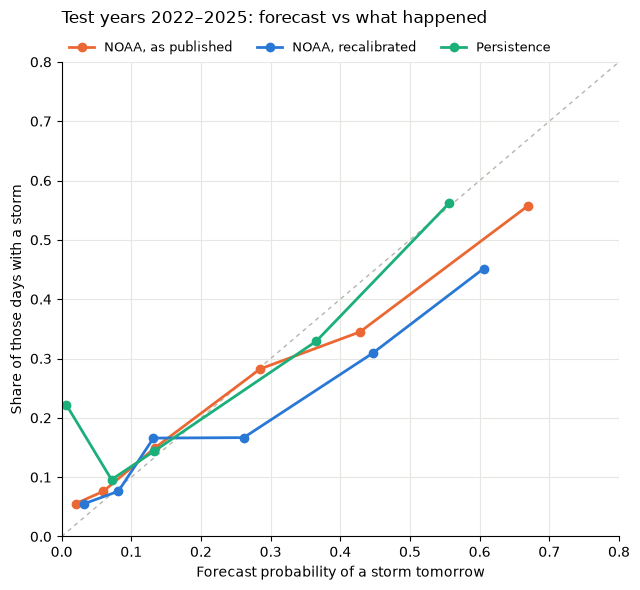

In [4]:
test_1 = period(forecasts, TEST)
test_1 = test_1[test_1["lead_days"] == 1]
bins = [0, 0.05, 0.1, 0.2, 0.35, 0.5, 1.0]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], color="#b5b5b0", linewidth=1, linestyle=(0, (3, 3)))
for key, color in (("noaa", "#eb6834"), ("noaa_recalibrated", "#2a78d6"), ("persistence", "#1baf7a")):
    groups = test_1.groupby(pd.cut(test_1[key], bins), observed=True)
    ax.plot(groups[key].mean(), groups["storm"].mean(), marker="o", color=color, linewidth=2, label=CONTENDERS[key])
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.8)
ax.set_xlabel("Forecast probability of a storm tomorrow")
ax.set_ylabel("Share of those days with a storm")
ax.set_title("Test years 2022–2025: forecast vs what happened", loc="left", pad=28)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1), ncols=3, borderaxespad=0.2, fontsize=9)
ax.grid(color="#e6e6e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## What this shows

- **NOAA's published forecast is the bar to clear.** It's the best of the five at every lead time: for tomorrow, its Brier skill over climatology is about 15% on 2017–2021 and 11% on 2022–2025. That's modest, and it fades with lead time, to about 3% three days ahead on the test years.
- **Recalibrating NOAA onto planetary Kp made it worse**, on both later periods. The mapping learned on 1996–2016 doesn't carry over, so NOAA's published numbers, already close to calibrated for Kp storms, are the benchmark from here on.
- **Persistence only helps for tomorrow.** Two or three days ahead, today's activity is worse than just knowing the base rate.
- **The 27-day echo alone is nearly worthless** (under 1% skill), despite the clear correlation in notebook 01: it's real, but small next to the day-to-day swings. It may still help alongside other signals.
- **The test years are much stormier**: 17% of days against 7% in 2017–2021, because they're this solar maximum. Skill scores are relative to each period's own climatology, so they stay comparable.

One thing NOAA has that none of these do: forecasters watch coronal mass ejections leave the Sun in coronagraph images, one to three days before they arrive. The next notebook tests how close a model can get, and whether it can beat NOAA, using only the data here.

## Saving the results

For the project's web page.

In [5]:
RESULTS = Path("..") / "results"
RESULTS.mkdir(exist_ok=True)
pd.concat({lead: score(period(forecasts, TEST)[period(forecasts, TEST)["lead_days"] == lead]) for lead in (1, 2, 3)},
          names=["lead days", "forecast"]).round(5).to_csv(RESULTS / "baseline_test_scores.csv")